# Step 0: Import requisite libraries

In [182]:
import json
import math
import pandas as pd
import numpy as np
import xgboost as xgb
from itertools import product
from sklearn import preprocessing, ensemble, tree
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, TunedThresholdClassifierCV
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, PrecisionRecallDisplay
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTETomek
import matplotlib.pyplot as plt
import seaborn as sns

threshold = 0.4

# Step 1: Import and cleaning of data

In [235]:
df_raw = pd.read_csv("Baza_customer_Telecom_v2.csv")

# Over+undersample by using combined SMOTE and Tomek links

df = df_raw
print(len(df))
df["CHURN"].value_counts()

8453


CHURN
No     7904
Yes     549
Name: count, dtype: int64

Length of dataset before cleaning: 8453
Length of dataset after cleaning: 8419


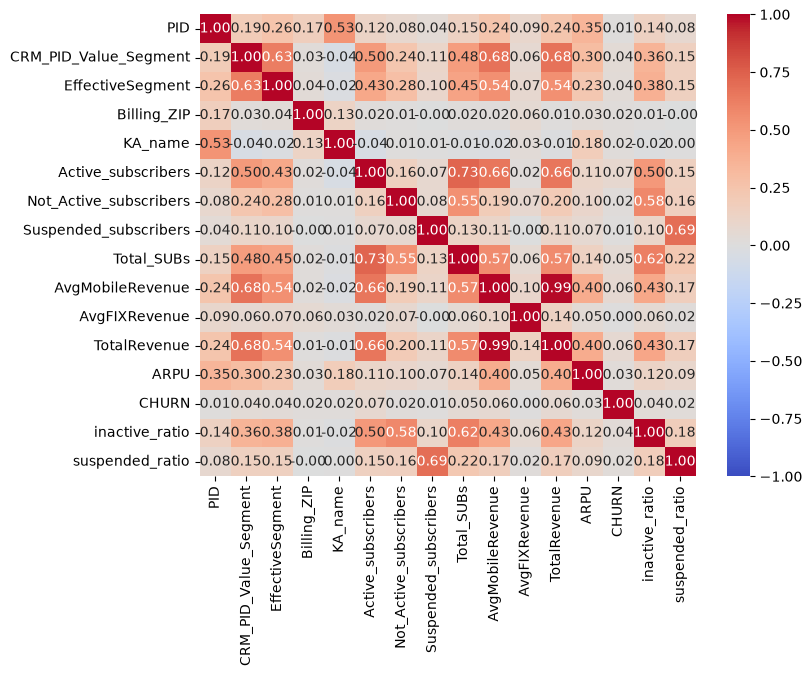

In [184]:
print(f"Length of dataset before cleaning: {len(df)}")
# Cleaning for PID
df = df.loc[df["PID"].notnull() & df["PID"].str.fullmatch(r"[0-9]*(SMB)?")] # Some PIDs were scientific notation (invalid); valid format is integer optionally followed by "SMB"

# Cleaning for value segment
df = df.loc[df["CRM_PID_Value_Segment"].notnull()]
df["CRM_PID_Value_Segment"] = df["CRM_PID_Value_Segment"].replace("Sliver", "Silver") # Fix assumed typo in one entry

# Cleaning for effective segment
df = df.loc[df["EffectiveSegment"].notnull()]

# Cleaning for ZIP
df = df.loc[df["Billing_ZIP"] % 1 == 0] # Remove non-integer ZIP codes (invalid; includes nulls)

# Cleaning for KA_name
df = df.loc[df["KA_name"].notnull()]
df["KA_name"] = df["KA_name"].replace("AD?", "AD") # Grouped AD? with AD under assumption that unsure attribution is correct

# Cleaning for active_subscribers
df = df.loc[df["Active_subscribers"].notnull()] # Redundant (no nulls) but included for consistency

# Cleaning for not_active_subscribers
df["Not_Active_subscribers"] = df["Not_Active_subscribers"].fillna(0) # Fill nulls with 0 (assuming nulls indicate none inactive; minimum non-NaN value is 1)

# Cleaning for suspended_subscribers
df["Suspended_subscribers"] = df["Suspended_subscribers"].fillna(0) # Fill nulls with 0 (assuming nulls indicate none suspended; minimum non-NaN value is 1)

# Cleaning for total_SUBs
df = df.loc[df["Total_SUBs"].notnull()] # Redundant (no nulls) but included for consistency

# Cleaning for AvgMobileRevenue
df = df.loc[df["AvgMobileRevenue "].notnull()] # Redundant (no nulls) but included for consistency
df = df.rename(columns={"AvgMobileRevenue ": "AvgMobileRevenue"}) # Remove trailing space from column name

# Cleaning for AvgFIXRevenue
df = df.loc[df["AvgFIXRevenue"].notnull()] # Redundant (no nulls) but included for consistency

# Cleaning for TotalRevenue
df = df.loc[df["TotalRevenue"].notnull()] # Redundant (no nulls) but included for consistency

# Cleaning for ARPU
df = df.loc[df["ARPU"].notnull()]

# Cleaning for CHURN
df = df.loc[df["CHURN"].isin(["No", "Yes"])] # Remove invalid CHURN values (only valid values are "No" and "Yes"); redundant (no invalids) but included for consistency

print(f"Length of dataset after cleaning: {len(df)}") # Small length change, hence valid to discard nulls/invalid entries

# Feature engineering
df["inactive_ratio"] = df["Not_Active_subscribers"]/df["Total_SUBs"]
df["suspended_ratio"] = df["Suspended_subscribers"]/df["Total_SUBs"]

# Source - https://stackoverflow.com/a/48035423
# Posted by BENY, modified by community. See post 'Timeline' for change history
# Retrieved 2026-09-02, License - CC BY-SA 4.0

segment_order = (df.groupby("CRM_PID_Value_Segment")["TotalRevenue"]
                 .mean()
                 .sort_values()
                 .index
                 .tolist())
corr = df.apply(lambda x : pd.factorize(x)[0]).corr(method='pearson', min_periods=1)
# Make heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.show()

# Step 2: Data Preprocessing

In [185]:
X = df.drop(columns=["CHURN"])
y = df["CHURN"].map({"No": 0, "Yes": 1}) # Convert CHURN to binary values (0 for No, 1 for Yes)

X["PID_is_SMB"] = X["PID"].str.endswith("SMB").astype("string") # Create binary feature indicating if PID ends with "SMB"
X["PID"]=X["PID"].str.replace("SMB", "").astype(int) # Remove "SMB" from PID and convert to integer

# Definition of categorical and numerical features for preprocessing
cat_features = [
    "CRM_PID_Value_Segment", 
    "EffectiveSegment", 
    "KA_name", 
    "PID_is_SMB"]
large_cat_features = [
    "Billing_ZIP"
]

num_features = [
    "Active_subscribers", 
    "Not_Active_subscribers", 
    "Suspended_subscribers", 
    "Total_SUBs", 
    "AvgMobileRevenue", 
    "AvgFIXRevenue", 
    "TotalRevenue", 
    "ARPU",
    ]

# Selection of features for model training

train_features = cat_features + large_cat_features + num_features

class_weights = {0: len(y == 1), 1: len(y == 0)}

train_features = [
    "PID_is_SMB",
    "CRM_PID_Value_Segment", 
    "Active_subscribers",
    "AvgMobileRevenue",
    "inactive_ratio",
    "suspended_ratio",
    "TotalRevenue"
    ]

X = X[train_features]

X.head()

,PID_is_SMB,CRM_PID_Value_Segment,Active_subscribers,AvgMobileRevenue,inactive_ratio,suspended_ratio,TotalRevenue
1,False,Bronze,3,40.17,0.000000,0.0,40.17
2,False,Bronze,2,40.17,0.600000,0.0,40.17
3,False,Bronze,1,40.17,0.666667,0.0,40.17
4,False,Iron,2,40.17,0.333333,0.0,40.17
5,False,Gold,2,40.17,0.846154,0.0,40.17


In [186]:


# Definition of ColumnTransformer for preprocessing
c_transformer = ColumnTransformer(
    transformers=[
        ("categorical", preprocessing.OneHotEncoder(handle_unknown="ignore"), list(set(cat_features) & set(train_features)) ),
        ("categorical_large", preprocessing.TargetEncoder(random_state=42), list(set(large_cat_features) & set(train_features))),
        ("numerical", "passthrough", list(set(num_features) & set(train_features)) )
    ]
)


# print(f"Column transformer has categorical features {list(set(cat_features) & set(train_features))} and numerical features {list(set(num_features) & set(train_features))}")


# XGBoost prep
for col in (set(cat_features) & set(train_features)):
    X[col] = X[col].astype('category')

smt = SMOTETomek(sampling_strategy=3/7, random_state=42)

# Train/test split
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)
# Fit preprocessor separately so the validation set can be transformed in the
# same way as the training set before each XGBoost eval round.
X_train_proc = c_transformer.fit_transform(X_train, y_train)
X_valid_proc = c_transformer.transform(X_valid)
X_test_proc = c_transformer.transform(X_test)

# Resample only the transformed training data. The validation/test sets should
# remain in their original class distribution for evaluation.
X_train_res, y_train_res = smt.fit_resample(X_train_proc, y_train)

# XGBoost model using a proper eval set.
clf = xgb.XGBClassifier(
    tree_method="hist",
    n_estimators=5000,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=1,
    subsample=0.7,
    colsample_bytree=0.7,
    reg_alpha=0.0,
    reg_lambda=3,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=(y_train_res == 0).sum() / (y_train_res == 1).sum(),
    early_stopping_rounds=500,
    random_state=42,
)

# Fit model using the transformed validation set.
clf.fit(
    X_train_res,
    y_train_res,
    eval_set=[(X_valid_proc, y_valid)],
    verbose=False,
)

# Predict on test set
y_pred_p = clf.predict_proba(X_test_proc)
t_df = pd.DataFrame(X_test)
t_df["Predicted_Churn_Probability"] = y_pred_p[:, 1] # Get probabilities for positive class (CHURN = Yes)
t_df["Predicted_Churn"] = (t_df["Predicted_Churn_Probability"] >= threshold).astype(int) # Convert probabilities to binary predictions using threshold of 0.5
t_df["Actual_Churn"] = y_test.values # Add actual CHURN values for comparison
t_df["Prediction_type"] = np.select(
    [
        (t_df["Predicted_Churn"] == 1) & (t_df["Actual_Churn"] == 1),
        (t_df["Predicted_Churn"] == 0) & (t_df["Actual_Churn"] == 0),
        (t_df["Predicted_Churn"] == 1) & (t_df["Actual_Churn"] == 0),
        (t_df["Predicted_Churn"] == 0) & (t_df["Actual_Churn"] == 1)
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ],
    default="Unknown"
)

# Evaluate model performance
y_pred = y_pred_p[:, 1] >= threshold
print(classification_report(y_test, y_pred))
print("Test confusion matrix with threshold", (str(threshold) + ":\n"), confusion_matrix(y_test, y_pred))
train_prob = clf.predict_proba(X_train_proc)[:, 1]
train_pred = (train_prob >= threshold).astype(int)
print(confusion_matrix(y_train, train_pred))
t_df.sort_values(by="Predicted_Churn_Probability", ascending=False).to_csv("Predicted_Churn_Results.csv", index=False) # Save predictions to CSV for further analysis
t_df.sort_values(by="Predicted_Churn_Probability", ascending=False).head(20) # Sort by predicted probability for easier analysis

              precision    recall  f1-score   support

           0       0.94      0.69      0.80      1575
           1       0.08      0.38      0.13       109

    accuracy                           0.67      1684
   macro avg       0.51      0.53      0.46      1684
weighted avg       0.89      0.67      0.76      1684

Test confusion matrix with threshold 0.4:
 [[1092  483]
 [  68   41]]
[[3517 1524]
 [ 168  179]]


,PID_is_SMB,CRM_PID_Value_Segment,Active_subscribers,AvgMobileRevenue,inactive_ratio,suspended_ratio,TotalRevenue,Predicted_Churn_Probability,Predicted_Churn,Actual_Churn,Prediction_type
4614,False,Gold,23,308.67,0.041667,0.000000,308.67,0.643220,1,0,False Positive
6972,False,Gold,24,311.67,0.111111,0.000000,311.67,0.643220,1,0,False Positive
4447,False,Gold,15,284.40,0.062500,0.000000,284.40,0.642508,1,0,False Positive
4544,False,Gold,15,298.00,0.318182,0.000000,298.00,0.642508,1,0,False Positive
4468,False,Gold,15,287.17,0.166667,0.000000,287.17,0.642508,1,0,False Positive
4425,False,Gold,15,281.17,0.210526,0.000000,281.17,0.637907,1,0,False Positive
4426,False,Gold,14,281.33,0.000000,0.000000,281.33,0.637907,1,0,False Positive
7693,False,Gold,16,294.50,0.333333,0.000000,294.50,0.636750,1,0,False Positive
4460,False,Gold,16,286.00,0.200000,0.000000,286.00,0.636750,1,0,False Positive
4604,False,Gold,16,307.50,0.111111,0.000000,307.50,0.636750,1,0,False Positive


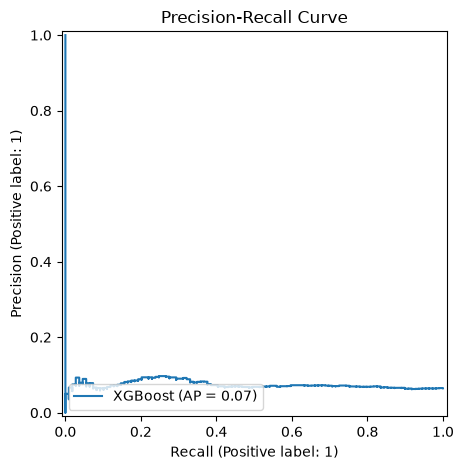

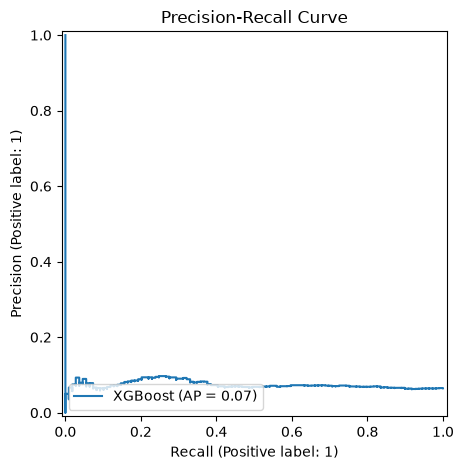

In [187]:
# Precision-recall curves require the positive-class probability, not both probability columns.
pr_display = PrecisionRecallDisplay.from_predictions(
    y_test,
    y_pred_p[:, 1],
    name="XGBoost",
)
pr_display.ax_.set_title("Precision-Recall Curve")
pr_display.ax_.figure.tight_layout()
pr_display.ax_.figure

In [188]:
t_df[t_df["Prediction_type"] == "True Positive"].sort_values(by="Predicted_Churn_Probability", ascending=False).head(20) # Sort by predicted probability for easier analysis

,PID_is_SMB,CRM_PID_Value_Segment,Active_subscribers,AvgMobileRevenue,inactive_ratio,suspended_ratio,TotalRevenue,Predicted_Churn_Probability,Predicted_Churn,Actual_Churn,Prediction_type
4664,False,Gold,15,316.33,0.062500,0.000000,316.33,0.628974,1,1,True Positive
4439,False,Gold,9,282.67,0.181818,0.000000,282.67,0.602222,1,1,True Positive
4390,False,Gold,18,276.67,0.095238,0.047619,276.67,0.593682,1,1,True Positive
4446,False,Gold,28,284.33,0.034483,0.000000,284.33,0.581079,1,1,True Positive
4192,False,Gold,14,248.50,0.066667,0.000000,248.50,0.565201,1,1,True Positive
3371,False,Silver,8,177.33,0.000000,0.000000,177.33,0.560922,1,1,True Positive
4155,False,Gold,13,244.17,0.133333,0.000000,244.17,0.553785,1,1,True Positive
3539,False,Silver,8,187.67,0.111111,0.000000,187.67,0.552182,1,1,True Positive
3712,False,Silver,13,203.33,0.066667,0.066667,203.33,0.535430,1,1,True Positive
3235,False,Silver,16,169.17,0.000000,0.058824,169.17,0.530092,1,1,True Positive


In [189]:
from sklearn.metrics import precision_score, recall_score

# Calculate evaluation metrics separately for each CRM value segment.
# The loop follows segment_order so auc_df keeps the business-defined ordering.
auc_rows = []
for segment in segment_order:
    # Select only test-set rows that belong to the current CRM segment.
    segment_mask = X_test["CRM_PID_Value_Segment"] == segment

    # Select the actual churn labels for this segment using the same mask.
    segment_actual = y_test[segment_mask]

    # y_pred_p contains two probability columns: column 0 for No churn and
    # column 1 for Yes churn. ROC-AUC must use the positive-class probability.
    segment_probability = y_pred_p[segment_mask.to_numpy(), 1]

    # Convert probabilities to binary predictions using the global threshold.
    # Precision and recall depend on this threshold; AUC does not.
    segment_prediction = segment_probability >= threshold

    # ROC-AUC is undefined when a segment contains only one actual class.
    # Store NaN for those segments instead of raising an exception.
    segment_auc = (
        roc_auc_score(segment_actual, segment_probability)
        if segment_actual.nunique() == 2
        else np.nan
    )

    # Store one result row for the current segment. Sample counts provide
    # context because metrics from very small segments are unstable.
    auc_rows.append({
        "Segment": segment,
        "AUC": segment_auc,
        "Precision": precision_score(
            segment_actual,
            segment_prediction,
            zero_division=0,
        ),
        "Recall": recall_score(
            segment_actual,
            segment_prediction,
            zero_division=0,
        ),
        "Samples": int(segment_mask.sum()),
        "Positive_samples": int(segment_actual.sum()),
    })

# Convert the collected rows into a DataFrame for comparison and display.
auc_df = pd.DataFrame(auc_rows)
# Add a row for total metrics as well
# More columns for comparison vs total dataset
auc_df

,Segment,AUC,Precision,Recall,Samples,Positive_samples
0,Iron,0.430000,0.000000,0.000000,52,2
1,Bronze,0.487111,0.093750,0.183673,752,49
2,Silver,0.716065,0.088785,0.826087,400,23
3,SE,NaN,0.000000,0.000000,13,0
4,Lead,NaN,0.000000,0.000000,6,0
5,Gold,0.556864,0.060811,0.473684,305,19
6,SME,0.399160,0.074074,0.285714,58,7
7,Platinum,0.373908,0.057143,0.222222,98,9


In [190]:
for segment in X["CRM_PID_Value_Segment"].unique():
    print(f"Confusion matrix for category {segment}:")
    print(confusion_matrix(y_test[X_test["CRM_PID_Value_Segment"] == segment], y_pred[X_test["CRM_PID_Value_Segment"] == segment]))
    print(f"Classification report for category {segment}:")
    print(classification_report(y_test[X_test["CRM_PID_Value_Segment"] == segment], y_pred[X_test["CRM_PID_Value_Segment"] == segment]))
    print()

Confusion matrix for category Bronze:
[[616  87]
 [ 40   9]]
Classification report for category Bronze:
              precision    recall  f1-score   support

           0       0.94      0.88      0.91       703
           1       0.09      0.18      0.12        49

    accuracy                           0.83       752
   macro avg       0.52      0.53      0.52       752
weighted avg       0.88      0.83      0.86       752


Confusion matrix for category Iron:
[[50  0]
 [ 2  0]]
Classification report for category Iron:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        50
           1       0.00      0.00      0.00         2

    accuracy                           0.96        52
   macro avg       0.48      0.50      0.49        52
weighted avg       0.92      0.96      0.94        52


Confusion matrix for category Gold:
[[147 139]
 [ 10   9]]
Classification report for category Gold:
              precision    recall  f1-score 

/Users/edano/Library/Mobile Documents/com~apple~CloudDocs/ResProj/ResProj.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/edano/Library/Mobile Documents/com~apple~CloudDocs/ResProj/ResProj.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/edano/Library/Mobile Documents/com~apple~CloudDocs/ResProj/ResProj.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in 

Index(['PID_is_SMB', 'CRM_PID_Value_Segment', 'Active_subscribers',
       'AvgMobileRevenue', 'inactive_ratio', 'suspended_ratio',
       'TotalRevenue'],
      dtype='str')


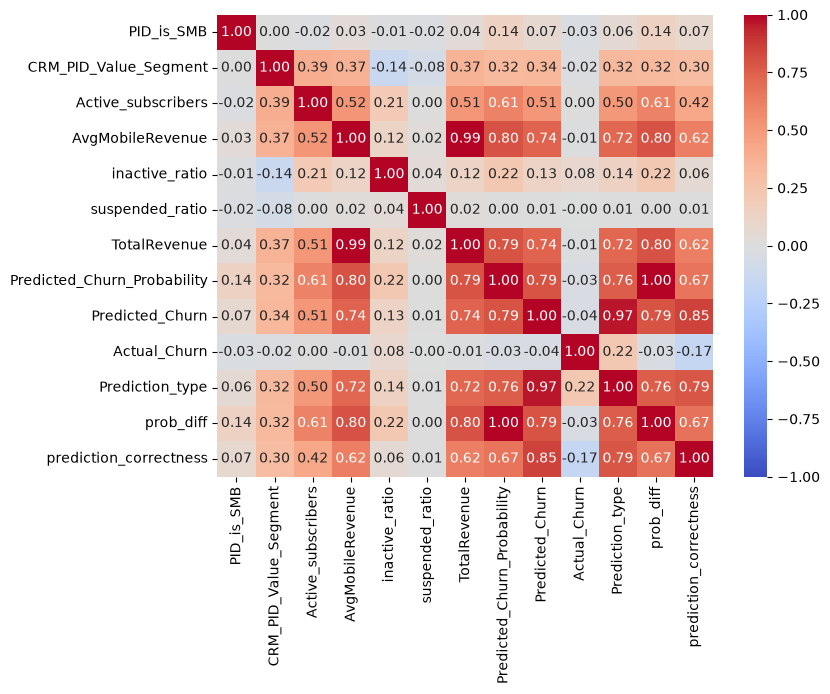

In [230]:
test_df = pd.read_csv("Predicted_Churn_Results.csv")
test_df["prob_diff"] = abs(test_df["Actual_Churn"] - test_df["Predicted_Churn_Probability"])
test_df["prediction_correctness"] = test_df["Prediction_type"].str.startswith("True")
from pandas.api.types import is_numeric_dtype

print(X_train.columns)
cols = X_train.columns.to_list()

# fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(10, 20))

# for col, ax in zip(cols, axes.ravel()):
#     ax.scatter(test_df[col], test_df["prob_diff"], color="royalblue")
#     ax.set_title(col)
#     ax.set_xlabel(col)
#     ax.set_ylabel("Probability")

# sns.pairplot(test_df, hue="CRM_PID_Value_Segment")
   
corr = test_df.apply(lambda x : pd.factorize(x)[0]).corr(method='pearson', min_periods=1)
# Make heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.show()

<Axes: xlabel='Samples', ylabel='AUC'>

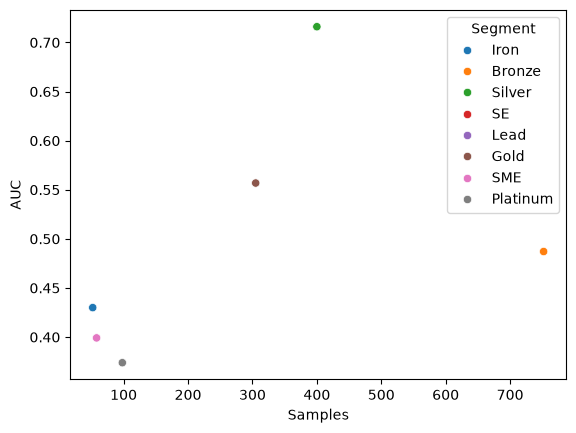

In [231]:
sns.scatterplot(data=auc_df, x="Samples", y="AUC", hue="Segment")

In [232]:
grouped = test_df.rename(columns={"CRM_PID_Value_Segment": "Segment"}).groupby(["Segment"]).mean(numeric_only=True)
meandiffs = pd.DataFrame()
for col in grouped.columns:
    meandiffs[col] = grouped[col] - grouped[col].mean()
meandiffs = pd.merge(meandiffs, auc_df, on="Segment").dropna()
grouped = pd.merge(grouped, auc_df, on="Segment").dropna()
grouped

,Segment,PID_is_SMB,Active_subscribers,AvgMobileRevenue,inactive_ratio,suspended_ratio,TotalRevenue,Predicted_Churn_Probability,Predicted_Churn,Actual_Churn,prob_diff,prediction_correctness,AUC,Precision,Recall,Samples,Positive_samples
0,Bronze,0.014628,4.683511,80.593231,0.145729,0.003190,80.892872,0.317389,0.127660,0.065160,0.341520,0.831117,0.487111,0.093750,0.183673,752,49
1,Gold,0.013115,11.580328,234.958230,0.181086,0.007284,235.436361,0.405678,0.485246,0.062295,0.415739,0.511475,0.556864,0.060811,0.473684,305,19
2,Iron,0.000000,4.576923,62.670962,0.173891,0.000000,64.911346,0.131743,0.000000,0.038462,0.161426,0.961538,0.430000,0.000000,0.000000,52,2
4,Platinum,0.000000,16.928571,372.792347,0.168672,0.013796,372.851837,0.353093,0.357143,0.091837,0.389739,0.591837,0.373908,0.057143,0.222222,98,9
6,SME,0.017241,16.637931,319.505690,0.260112,0.009965,322.117759,0.378202,0.465517,0.120690,0.417206,0.482759,0.399160,0.074074,0.285714,58,7
7,Silver,0.005000,7.337500,146.544550,0.157907,0.009905,147.050375,0.376275,0.535000,0.057500,0.381588,0.502500,0.716065,0.088785,0.826087,400,23


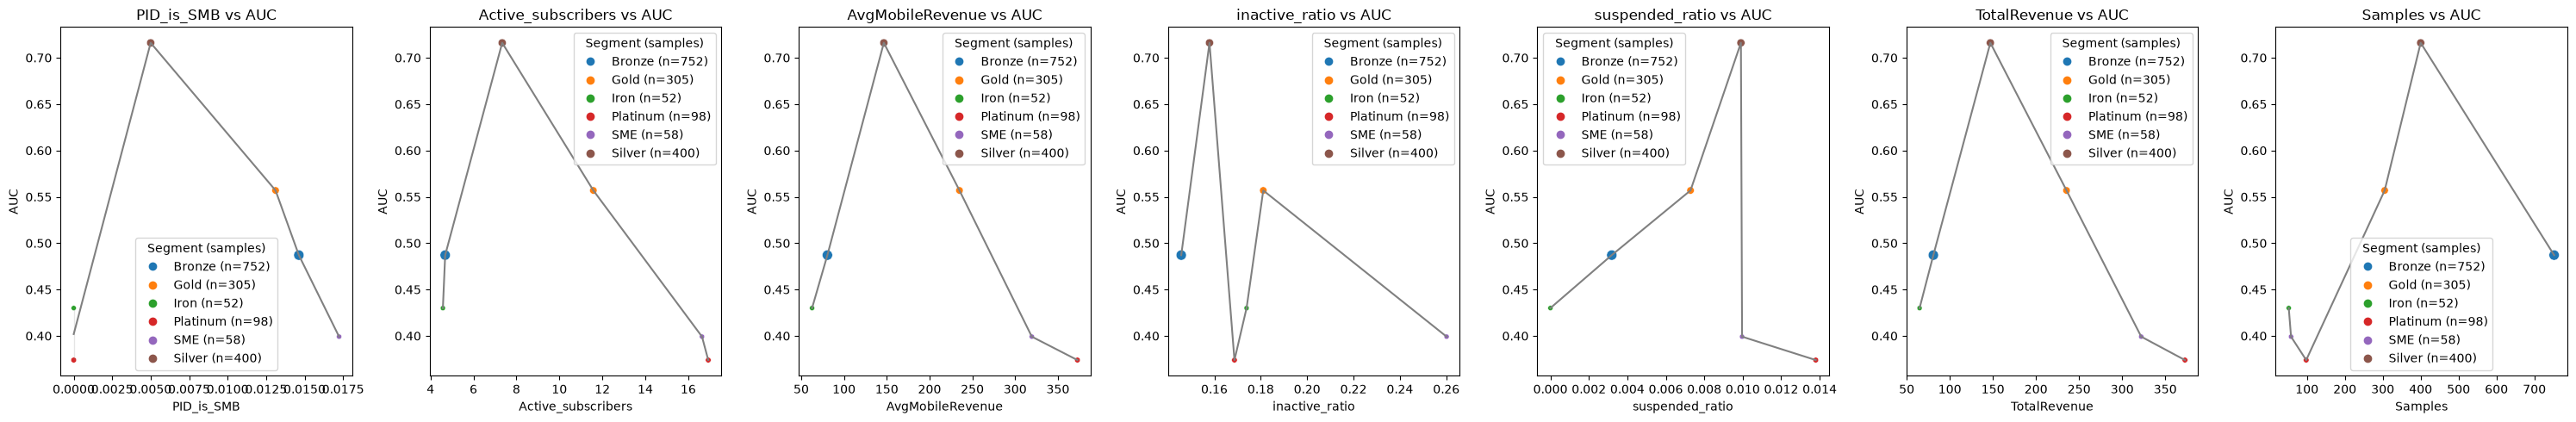

In [233]:
from matplotlib.lines import Line2D

target = "AUC"
features = ["PID_is_SMB", "Active_subscribers", "AvgMobileRevenue", "inactive_ratio", "suspended_ratio", "TotalRevenue", "Samples"]

segment_counts = grouped.groupby("Segment", sort=False)["Samples"].first()
segment_palette = dict(zip(segment_counts.index, sns.color_palette(n_colors=len(segment_counts))))
legend_handles = [
    Line2D([], [], marker="o", linestyle="None", color=segment_palette[segment],
           label=f"{segment} (n={int(samples):,})")
    for segment, samples in segment_counts.items()
]

fig, axes = plt.subplots(nrows=1, ncols=len(features), figsize=(30, 5))

for i, col in enumerate(features):
    sns.scatterplot(
        data=grouped, x=col, y=target, ax=axes[i], hue="Segment",
        palette=segment_palette, size="Samples", legend=False
    )
    axes[i].set_title(f"{col} vs {target}")
    axes[i].legend(handles=legend_handles, title="Segment (samples)")
    sns.lineplot(
        data=grouped, x=col, y=target, ax=axes[i], color="gray",
        legend=False
    )

plt.tight_layout()
plt.show()

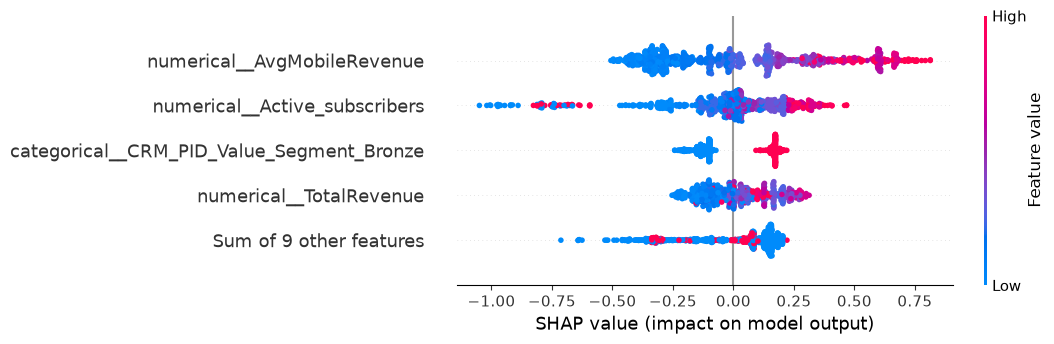

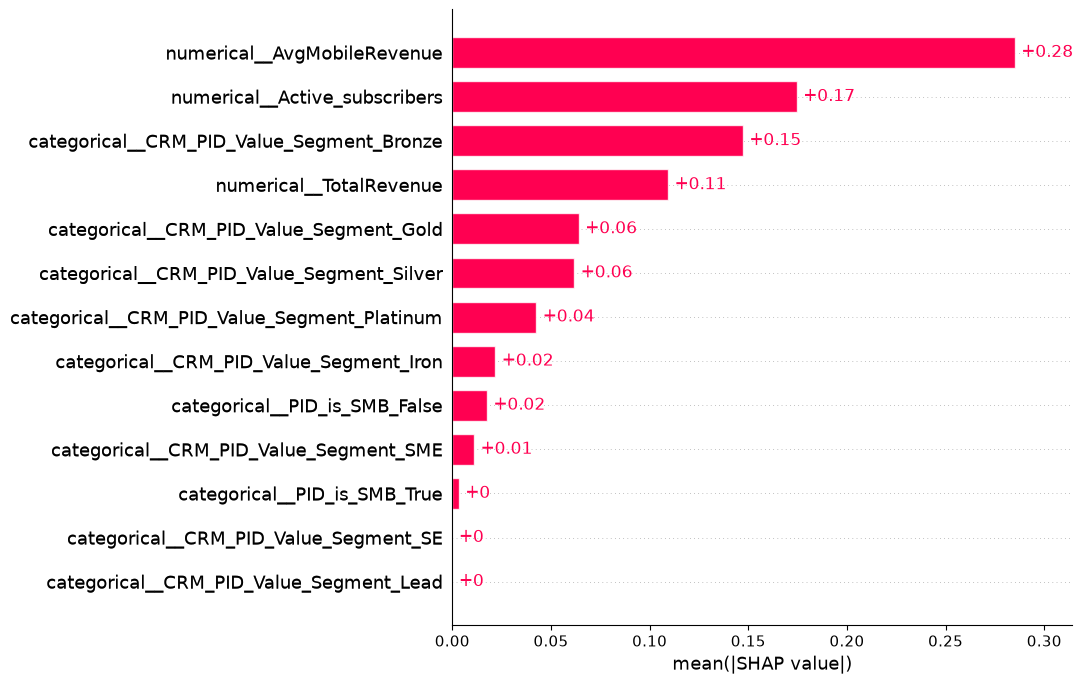

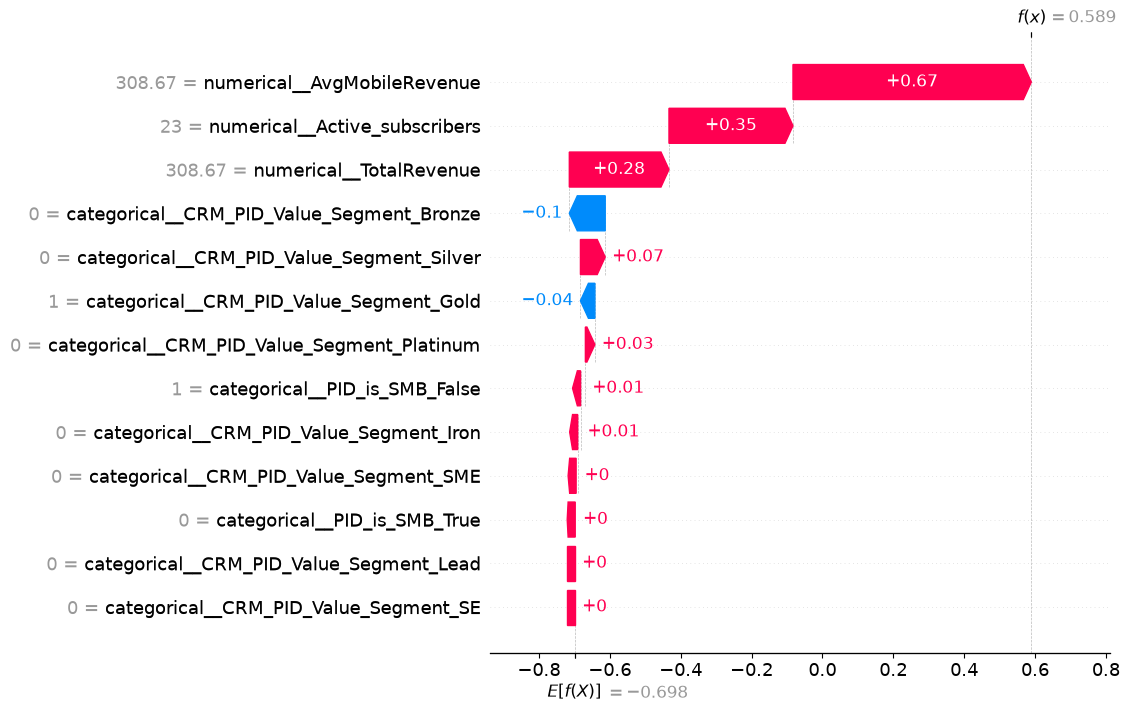

In [237]:
# NOTE: code in this cell created by copilot
import shap

# Explain the same numeric features that were used to train the classifier.
feature_names = c_transformer.get_feature_names_out()
background = shap.sample(X_train_proc, min(100, len(X_train_proc)), random_state=42)
X_shap = shap.sample(X_test_proc, min(1000, len(X_test_proc)), random_state=42)

explainer = shap.TreeExplainer(
    clf,
    data=background,
    feature_names=feature_names,
    feature_perturbation="interventional",
    model_output="raw",
)
shap_values = explainer(X_shap)

# Global view: impact and average absolute impact for each transformed feature.
shap.plots.beeswarm(shap_values, max_display=5)
shap.plots.bar(shap_values, max_display=20)

# Local view: explain the highest predicted churn probability in the sample.
high_risk_index = int(np.argmax(clf.predict_proba(X_shap)[:, 1]))
shap.plots.waterfall(shap_values[high_risk_index], max_display=20)